# Nivell 1

## Ex1 Niv1 Preguntes analítiques directes (sense integracions complexes)

In [1]:
# %pip install mysql-connector-python

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import mysql.connector
from getpass import getpass

In [3]:
import os
import socket
import sys

print("Equip:", socket.gethostname())
print("Python:", sys.executable)
print("Usuari:", os.getenv("USERNAME") or os.getenv("USER"))

Equip: LAPTOP-F2T41USD
Python: c:\Users\eduar\AppData\Local\Programs\Python\Python311\python.exe
Usuari: eduar


In [4]:
#installing sqlalchemy. It's commented as we only need to install it once
# %pip install sqlalchemy pymysql

In [5]:

# Conexión a MySQL
connection = mysql.connector.connect(
host="localhost",
port=3306,
user="root",
# password=getpass("Password: "),
password="psw12345$",
# database="transactions"
database="sprint2db"
)
# Comprobar conexión
print("Connection working?:", connection.is_connected())

Connection working?: True


### Ex1.1  Com evoluciona el nombre de transaccions al llarg del temps? Exemple de passos guiats amb pandas.

Preguntes analítiques: (només utilitzant la taula de transaccions) :

In [6]:
df_tr = pd.read_sql("SELECT * FROM transaction", connection)

C:\Users\eduar\AppData\Local\Temp\ipykernel_3828\4193330721.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_tr = pd.read_sql("SELECT * FROM transaction", connection)


    Selecciona la columna temporal adequada.
- Columna timestamp (datetime Dtype)

In [7]:
df_tr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99999 entries, 0 to 99998
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                99999 non-null  object        
 1   card_id           99999 non-null  object        
 2   business_id       99999 non-null  object        
 3   timestamp         99999 non-null  datetime64[ns]
 4   amount            99999 non-null  float64       
 5   declined          99999 non-null  int64         
 6   product_ids       99999 non-null  object        
 7   user_id           99999 non-null  object        
 8   lat               99999 non-null  float64       
 9   longitude         99999 non-null  float64       
 10  discount_amount   99999 non-null  float64       
 11  tax_amount        99999 non-null  float64       
 12  shipping_amount   99999 non-null  float64       
 13  channel           99999 non-null  object        
 14  campaign_id       9999

    Defineix el nivell temporal d'anàlisi.

In [8]:
df_tr['year'] = df_tr['timestamp'].dt.year

df_tr["year"].value_counts()


year
2021    10298
2022    10106
2020    10093
2019    10015
2023     9985
2024     9951
2017     9915
2018     9912
2015     9870
2016     9854
Name: count, dtype: int64

- Checking any possible null dates

In [9]:
df_tr["timestamp"].isna().sum()

0

- A single transaction exists in 2026. As it represents incomplete yearly data, it was excluded from the dataframe to avoid creating columns for just one transaction in a year.

In [10]:
df_tr = df_tr[df_tr["year"] != 2026]

    Compta el nombre de registres per període temporal.

In [11]:
transactions_year = df_tr.groupby('year').size()
# transactions_month = df_tr.groupby('month').size()
transactions_year
# transactions_month

year
2015     9870
2016     9854
2017     9915
2018     9912
2019    10015
2020    10093
2021    10298
2022    10106
2023     9985
2024     9951
dtype: int64

    Ordena els resultats cronològicament.

In [12]:
transactions_year

year
2015     9870
2016     9854
2017     9915
2018     9912
2019    10015
2020    10093
2021    10298
2022    10106
2023     9985
2024     9951
dtype: int64

    Visualitza l'evolució amb un gràfic de línies amb pandas.

<Axes: xlabel='year'>

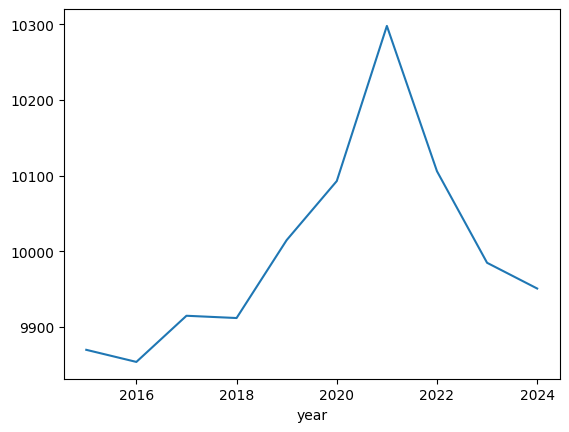

In [13]:
transactions_year.plot(kind='line')
# transactions_month.plot(kind='line')

> Conclusion: The number of transactions had an increasing tendency that spiked in 2021 but went down equally until 2024

### <span style="color: yellow;"> Ex1.2 Niv1. Quins usuaris generen més volum de facturació? Exemple de passos guiats amb seaborn. 



    Identifica la columna que representa el usuari.
- El usuario se identifica en la columna user_id


In [14]:
df_tr.columns

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'year'],
      dtype='object')

    Agrupa les transaccions per usuari i calcula el volum total de facturació sumant la columna amount.


In [15]:
df_tr.groupby("user_id")["amount"].sum().reset_index()

,user_id,amount
0,1,8146.82
1,10,7234.72
2,100,8754.22
3,1000,4887.31
4,1001,4768.28
...,...,...
4995,995,6995.00
4996,996,6685.46
4997,997,7044.52
4998,998,4270.64


    Ordena els usuaris de major a menor volum de facturació.


In [16]:
df_tr.groupby("user_id")["amount"].sum().reset_index().sort_values(by='amount', ascending=False, ignore_index=True)

,user_id,amount
0,289,47332.90
1,318,47133.55
2,455,41396.68
3,417,37393.91
4,185,34576.49
...,...,...
4995,3652,1432.29
4996,1306,1421.15
4997,1995,1405.70
4998,3119,1327.53


    Selecciona els N usuaris principals (per exemple, els 15 primers).
    Representa el resultat mitjançant un gràfic de barres utilitzant Seaborn


<Axes: xlabel='user_id', ylabel='amount'>

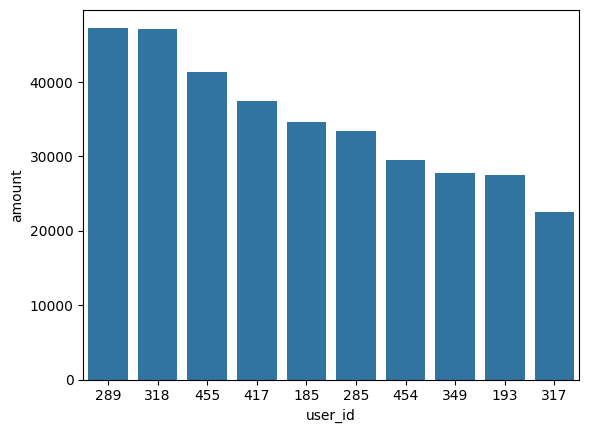

In [17]:
group = df_tr.groupby("user_id")["amount"]\
    .sum()\
    .reset_index()\
    .sort_values(by='amount', ascending=False, ignore_index=True)\
    .head(10)

sns.barplot(data=group, x="user_id", y="amount", order=group["user_id"])



### Ex1.3. Hi ha diferències en la distribució de l'import de les transaccions segons l'hora del dia i si han estat acceptades o rebutjades? Exemple de passos guiats amb seaborn.



        Crea una nova columna amb l'hora del dia a partir del timestamp.


In [18]:
df_tr['hour'] = df_tr['timestamp'].dt.hour
df_tr["hour"]

0         7
1        15
2        19
3        18
4         4
         ..
99994    20
99995     3
99996     2
99997    19
99998    12
Name: hour, Length: 99999, dtype: int32

        Utilitza un violinplot de seaborn per analitzar la distribució dels imports.


<Axes: xlabel='year', ylabel='amount'>

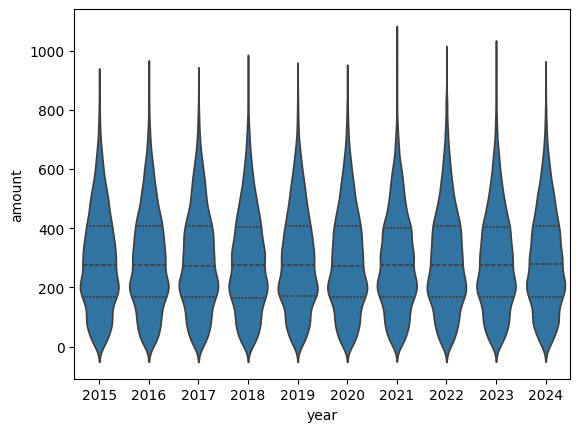

In [19]:
sns.violinplot(x="year", y="amount", data=df_tr, inner="quart")

        Assigna: x per l'hora del dia, y per l'import de la transacció i hue per l'estat de la transacció.


In [20]:
df_tr.columns

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'year', 'hour'],
      dtype='object')

In [21]:
df_tr["declined"].unique()


array([0, 1], dtype=int64)

In [22]:
# %matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns


<Axes: xlabel='hour', ylabel='amount'>

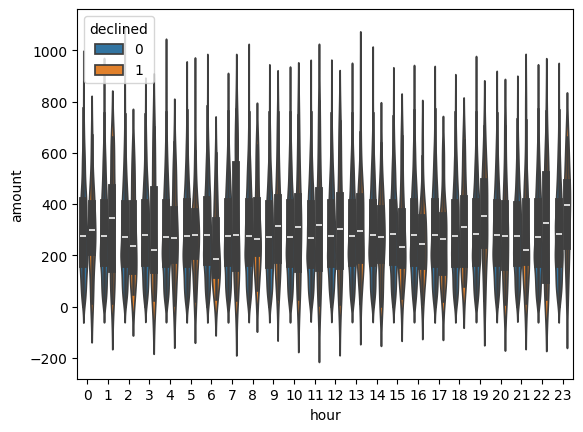

In [23]:
sns.violinplot(
    x="hour",       
    y="amount",
    hue="declined",  
    data=df_tr,
)

# plt.title("Distribució dels imports per hora i estat de la transacció")
# plt.show()

        Activa split per comparar acceptades i rebutjades i inner amb quartile per mostrar mediana i quartils.


<Axes: xlabel='hour', ylabel='amount'>

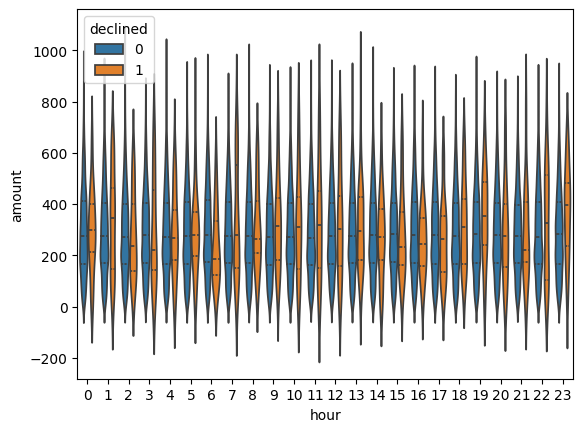

In [24]:
sns.violinplot(
    x="hour",       
    y="amount",
    hue="declined",  
    data=df_tr,
    inner="quart",
    split=False
)


    4. Quins dies de la setmana es concentra més activitat de venda?

    👉 Per a cada pregunta:

        Construeix una visualització senzilla en Python sense utilitzar IA.
        Interpreta breument el resultat obtingut.
        Utilitza les eines d'IA disponibles a Colab per proposar una visualització alternativa.



- mi intento: sns.countplot: Cuenta directamente cuántos registros (filas) existen para cada day.

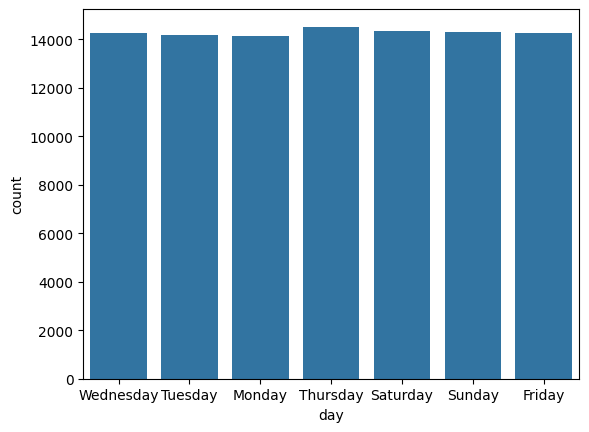

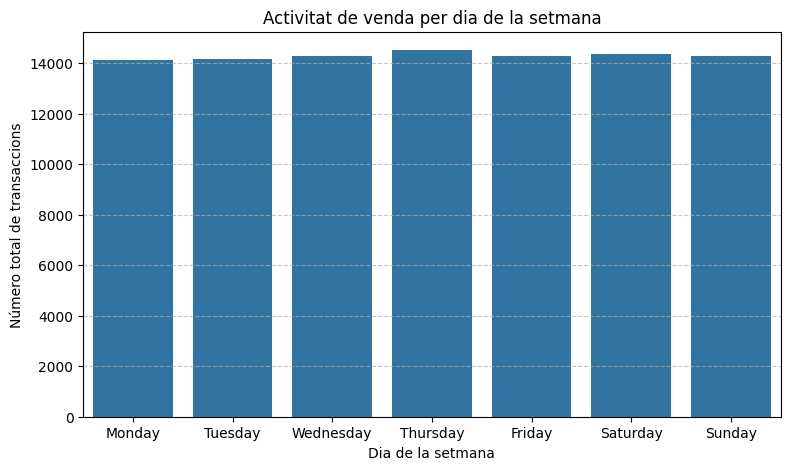

In [25]:
# Mi intento 
df_tr["day"] = df_tr["timestamp"].dt.day_name()

sns.countplot(
    x="day", 
    data=df_tr
)

# Con IA
# 1. Assegurar format datetime i extreure el nom del dia en anglès (per defecte)
# df_tr["timestamp"] = pd.to_datetime(df_tr["timestamp"])
df_tr["day"] = df_tr["timestamp"].dt.day_name()

# 2. Definir l'ordre cronològic correcte per a l'eix X
dies_ordre = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

# 3. Agrupar i comptar el volum d'activitat (transaccions)
group = (
    df_tr.groupby("day", observed=False)["id"]
    .count()
    .reset_index(name="total_transaccions")
)

# 4. Crear el gràfic de barres bàsic
plt.figure(figsize=(9, 5))
sns.barplot(x="day", y="total_transaccions", data=group, order=dies_ordre)

plt.title("Activitat de venda per dia de la setmana")
plt.xlabel("Dia de la setmana")
plt.ylabel("Número total de transaccions")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


        Compara el resultat inicial amb el resultat proposat per la IA i valora críticament si la nova proposta és una millora o un empitjorament, justificant la teva decisió.
- Ambos gráficos indica que el día con más número de ventas es el Jueves pero se lee mucho mejor el generado por la IA ya q es capaz de ordenar los días de lunes a domingo y además añade líneas discontinuas que ayudan a saber cual es la cantidad de transacciones.

## Ex 2 Niv1: Preguntes analítiques complexes (amb guia)

    🌍 Context: Aquest exercici requereix combinar informació de diverses taules del model per poder respondre correctament les preguntes.

Aquí sí que serà necessari:

    » Fer merge entre taules.

    » Utilitzar groupby, pivot_table, crosstab...

    » Aplicar agregacions, transformacions intermèdies i funcions.


    Preguntes analítiques (amb guia general)


### Depenem excessivament d'un nombre reduït de països de companyies venedores?

Passos orientatius:

    1. Combinar la informació de transaccions amb la de companyies


- They are asking us to use merge. So, instead of doing an SQL JOIN query, we load the companies table separately and merge them using Python.


In [26]:
df_co = pd.read_sql("SELECT * FROM company", connection)

C:\Users\eduar\AppData\Local\Temp\ipykernel_3828\2133817695.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_co = pd.read_sql("SELECT * FROM company", connection)


- We inspect the columns in both DataFrames to determine the matching keys for the merge

In [27]:
df_tr.info()
df_co.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99999 entries, 0 to 99998
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                99999 non-null  object        
 1   card_id           99999 non-null  object        
 2   business_id       99999 non-null  object        
 3   timestamp         99999 non-null  datetime64[ns]
 4   amount            99999 non-null  float64       
 5   declined          99999 non-null  int64         
 6   product_ids       99999 non-null  object        
 7   user_id           99999 non-null  object        
 8   lat               99999 non-null  float64       
 9   longitude         99999 non-null  float64       
 10  discount_amount   99999 non-null  float64       
 11  tax_amount        99999 non-null  float64       
 12  shipping_amount   99999 non-null  float64       
 13  channel           99999 non-null  object        
 14  campaign_id       9999

- We will merge the data using the company_id column from the transactions dataframe and the id column from the companies dataframe.

In [28]:
df_merged = pd.merge(
    df_tr,
    df_co,
    left_on="business_id", # sprint2db
    # left_on="company_id",  # transactions db
    right_on="id",
    how="left"
)
df_merged

,id_x,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,hour,day,id_y,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16,26,97,87",4713,46.1999,1.43554,...,7,Wednesday,b-2458,Eget Tincidunt Dui Institute,+18 210 327 5206,eget.laoreet@hotmail.org,Netherlands,https://www.eget-tincidunt-dui-institute.com,Toys,mid-market
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30,11,16,81",2118,29.7573,-95.37960,...,15,Tuesday,b-2390,Neque Tellus Imperdiet Corp.,+12 445 145 3593,vestibulum.ante.ipsum@aol.edu,Ireland,https://www.neque-tellus-imperdiet-corp.com,Food,budget
2,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2017-09-04 19:44:53,175.00,0,72,2115,53.5489,-113.50300,...,19,Monday,b-2230,Fusce Corp.,+29 657 646 4324,risus@protonmail.edu,United States,https://www.fusce-corp.com,Home,mid-market
3,00051AA4-9CBE-4268-B070-C38062A1B3E2,CcS-7606,b-2266,2017-01-05 18:19:25,158.55,0,18,3025,52.2084,5.69081,...,18,Thursday,b-2266,Mus Aenean Eget Foundation,+1 504 922 3000,mi.duis@hotmail.net,Sweden,https://www.mus-aenean-eget-foundation.com,Sports,mid-market
4,0008A312-EDFE-4A4F-BC99-E9C92EC3CA4D,CcU-3358,b-2598,2023-09-23 04:51:43,317.97,0,"35,33,19",215,53.5535,-113.49900,...,4,Saturday,b-2598,Aliquam Iaculis Lacus Corp.,+23 674 242 3712,dictum@aol.org,Belgium,https://www.aliquam-iaculis-lacus-corp.com,Fashion,budget
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99994,FFF9E3CE-234E-408C-A8EF-F9CAD577224A,CcS-5010,b-2234,2022-12-17 20:57:55,278.42,0,"20,42,54,46",429,52.5223,13.40490,...,20,Saturday,b-2234,Convallis In Incorporated,+6 693 982 1255,mauris.ut@aol.couk,Germany,https://www.convallis-in-incorporated.com,Sports,mid-market
99995,FFFB270D-F53A-4D5D-9666-E5307C53CC84,CcS-7655,b-2522,2024-05-13 03:42:03,403.66,0,"30,87,5,66",3074,39.0271,-8.10523,...,3,Monday,b-2522,Viverra Donec Foundation,+97 631 212 7283,dictum.eu@outlook.net,United Kingdom,https://www.viverra-donec-foundation.com,Fashion,budget
99996,FFFC9E8D-27C7-4ADE-98F2-7533EF4DF126,CcS-5589,b-2302,2019-10-30 02:31:37,295.43,0,"16,49",1008,59.3327,18.07530,...,2,Wednesday,b-2302,Nunc Interdum Incorporated,+54 217 870 5363,non@outlook.com,Germany,https://www.nunc-interdum-incorporated.com,Sports,budget
99997,FFFCF76D-ECF0-4985-A2D0-B2A7B75998FC,CcS-5261,b-2250,2023-06-17 19:10:30,183.02,0,18,680,52.0635,4.30862,...,19,Saturday,b-2250,Amet Nulla Donec Corporation,+96 338 276 8449,mattis.integer.eu@protonmail.net,Italy,https://www.amet-nulla-donec-corporation.com,Gaming,budget


    2. Agrupar la facturació per país.
    3. Calcular la facturació total generada per cada país.
    4. Ordenar els països de major a menor facturació.


In [29]:
revenue_country = (
    df_merged.groupby("country")["amount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

revenue_country


,country,amount
0,Sweden,4928117.68
1,Netherlands,4506571.38
2,United Kingdom,4099117.08
3,Italy,4087557.38
4,Germany,4020364.07
5,France,1416084.26
6,United States,1101737.27
7,Belgium,952208.75
8,Norway,809288.82
9,Ireland,715220.46


    5. Calcular el percentatge acumulat sobre el total.

In [30]:
#total 
revenue_total = revenue_country["amount"].sum().round(0)
# revenue_total.dtype
revenue_total

29295302.0

In [31]:
revenue_country["percentage"] = (
    (revenue_country["amount"] / revenue_total) * 100).round(0)

revenue_country


,country,amount,percentage
0,Sweden,4928117.68,17.0
1,Netherlands,4506571.38,15.0
2,United Kingdom,4099117.08,14.0
3,Italy,4087557.38,14.0
4,Germany,4020364.07,14.0
5,France,1416084.26,5.0
6,United States,1101737.27,4.0
7,Belgium,952208.75,3.0
8,Norway,809288.82,3.0
9,Ireland,715220.46,2.0


    6. Visualitzar.



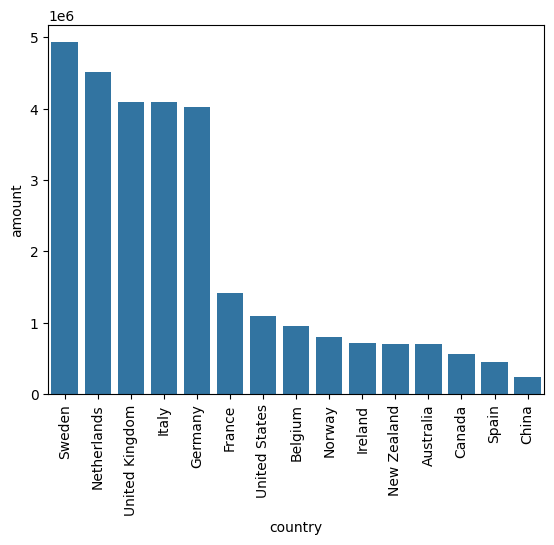

In [32]:
#pandas 
# revenue_country.plot(kind='bar', x="country", y="amount", rot=90)

#visuals with seaborn
sns.barplot(
    data=revenue_country,
    x="country",
    y="amount"
    )
#display names vertically on x axis
plt.xticks(rotation=90)
plt.show()

### Is there seasonality in sales?

Guiding Steps

 1. Work with transaction dates.

- Ensure the DateTime column is stored in a datetime format so that Pandas `.dt` methods can be used.
  - Example: `2024-08-28 07:16:46`

 2. Extract the relevant temporal information (year and month).

- Create separate columns for the transaction year and month using the timestamp column.
- These variables will be used to identify temporal patterns and analyze seasonality.

 3. Calculate total sales volume (sum of `amount`) by year and month.

- Group transactions by year and month.
- Sum the values in the `amount` column for each year-month combination.
- This creates an aggregated table showing monthly sales revenue over time.

In [33]:
df_tr["month"] = df_tr["timestamp"].dt.month
df_tr["year"] = df_tr["timestamp"].dt.year

In [34]:
# Groups transactions by month and year, then calculates the total sales amount for each month-year combination. This creates a summarized table of monthly revenue over time.
sales_by_month = ( 
    df_tr.groupby(
        [df_tr["month"], df_tr["year"]]
        )["amount"]
    .sum()
    .reset_index()
)

# sales_by_month
# sales_by_month.plot(kind="bar", x="month", y="amount")

# Groups all months together across different years and sums their sales. This allows us to identify seasonal patterns and determine which months tend to generate more revenue overall.
sales_by_month_and_year = ( 
    sales_by_month.groupby(sales_by_month["month"])["amount"]
    .sum()
    .reset_index()
)


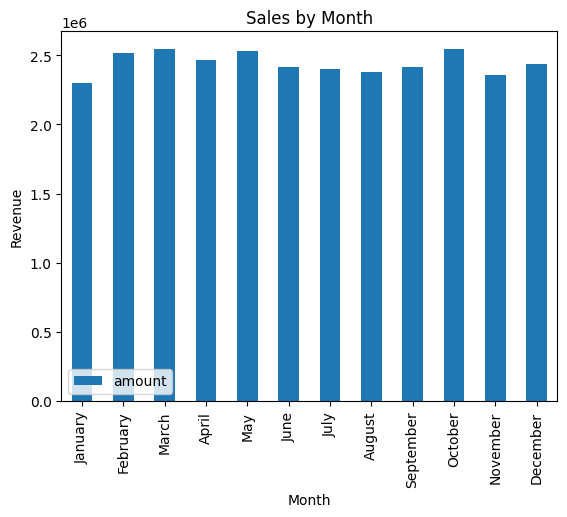

In [35]:
# For a better readibilty, we create a dictionary in order to show month names intead of month numbers. 
month_dict = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}
# mapping the month column (number) with the dictionary
sales_by_month_and_year["month_name"] = sales_by_month_and_year["month"].map(month_dict)

# Customizes the chart by adding a title, labeling the axes, and positioning the legend in the lower-left corner for better readability.
ax = sales_by_month_and_year.plot(kind="bar", x="month_name", y="amount")
ax.set_title("Sales by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.legend(loc="lower left")

plt.show()


In [36]:
sales_by_month.tail()

,month,year,amount
115,12,2020,246449.95
116,12,2021,243737.57
117,12,2022,239045.01
118,12,2023,236690.04
119,12,2024,251688.94


4. Compare temporal patterns across years. Create a pivot table.
- A pivot table is useful because it places years side by side, making patterns much easier to compare.

- Create a pivot table with months as rows and years as columns.
- Fill the table with total sales amounts.
- Use the resulting table to compare monthly sales patterns across different years and identify recurring seasonal trends.

5. Visualitzar l'evolució.


In [37]:
pivot_table = sales_by_month.pivot_table(
    values="amount", 
    index="month", 
    columns="year"
)
pivot_table.head().style.format("{:,.0f}")

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
month,,,,,,,,,,
1,"224,946","227,231","224,391","229,524","224,593","234,191","246,994","226,681","231,076","227,399"
2,"248,776","251,111","253,355","246,505","262,007","249,356","258,837","237,503","252,680","253,740"
3,"254,703","248,246","240,338","239,146","280,530","260,821","253,111","274,387","243,910","248,589"
4,"247,957","242,394","253,126","237,432","244,348","246,533","261,597","241,191","245,387","245,734"
5,"252,596","243,534","240,919","246,838","244,740","254,171","243,415","279,590","264,790","257,877"


- Visualization

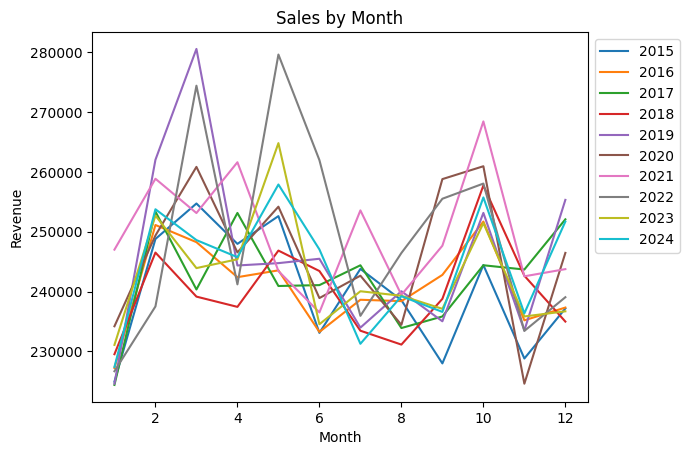

In [38]:
ax = pivot_table.plot(kind="line")
ax.set_title("Sales by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.legend(bbox_to_anchor=(1, 1), loc="upper left")

plt.show()


- The chart above it is not very insightful so we create a heatmap

5. Visualization with seaborn heatmap
- No clear seasonality is observed in the heatmap, as high and low sales periods do not consistently occur in the same months across different years.


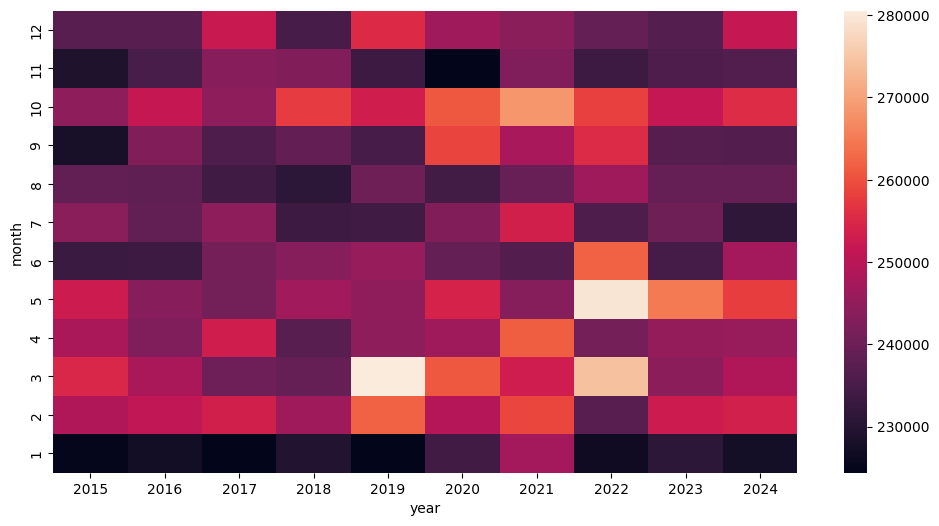

In [39]:
plt.figure(figsize=(12, 6))
ax = sns.heatmap(pivot_table)
ax.invert_yaxis()

### Concentration and Variability Analysis (Choose ONE option)



Option A - Product Analysis (Only if you have the products table)

**Question:** Which products generate the most revenue and with what level of variability?

Guiding Steps

---



1. Combine transactions, the bridge table, and products.


In [40]:
# Importing the products table and the bridge table so we can group the amount per product
# df_pr = pd.read_sql("SELECT * FROM product", connection) #transaction db
df_pr = pd.read_sql("SELECT * FROM products", connection) #sprint2db db
df_bridge_tr_pr = pd.read_sql("SELECT * FROM transaction_products", connection)


C:\Users\eduar\AppData\Local\Temp\ipykernel_3828\3309142281.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pr = pd.read_sql("SELECT * FROM products", connection) #sprint2db db
C:\Users\eduar\AppData\Local\Temp\ipykernel_3828\3309142281.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_bridge_tr_pr = pd.read_sql("SELECT * FROM transaction_products", connection)


In [41]:
#checking name of olumns 
df_tr.columns
df_bridge_tr_pr.columns
df_pr.columns

Index(['id', 'product_name', 'priceDollars', 'colour', 'weight',
       'warehouse_id', 'category', 'brand', 'costDollars', 'launch_date'],
      dtype='object')

In [42]:
df_pr.head(5)

,id,product_name,priceDollars,colour,weight,warehouse_id,category,brand,costDollars,launch_date
0,1,Direwolf Stannis,161.11,#7c7c7c,1.0,WH-4,Sports,Runway Pro,63.84,2014-11-01
1,2,Tarly Stark,9.24,#919191,2.0,WH-3,Gaming,Questbyte,4.74,2013-02-07
2,3,duel tourney Lannister,171.13,#d8d8d8,1.5,WH-2,Food,Daily Pantry,107.07,2013-08-18
3,4,warden south duel,71.89,#111111,3.0,WH-1,Books,NorthPress,39.17,2013-12-31
4,5,skywalker ewok,171.22,#dbdbdb,3.2,WH-0,Home,NordHaus,83.69,2014-07-17


In [43]:
df_merged = df_tr.merge(right=df_bridge_tr_pr, how="inner", left_on="id", right_on="transaction_id")
# 16,26,97,87 00043A49-2949-494B-A5DD-A5BAE3BB19DD
df_merged[["transaction_id", "product_id"]].head(5)
df_merged.head(5)

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,device_type,is_international,decline_reason,distance_km,year,hour,day,month,transaction_id,product_id
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16,26,97,87",4713,46.1999,1.43554,...,mobile,0,,59.95,2024,7,Wednesday,8,00043A49-2949-494B-A5DD-A5BAE3BB19DD,16
1,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16,26,97,87",4713,46.1999,1.43554,...,mobile,0,,59.95,2024,7,Wednesday,8,00043A49-2949-494B-A5DD-A5BAE3BB19DD,26
2,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16,26,97,87",4713,46.1999,1.43554,...,mobile,0,,59.95,2024,7,Wednesday,8,00043A49-2949-494B-A5DD-A5BAE3BB19DD,87
3,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16,26,97,87",4713,46.1999,1.43554,...,mobile,0,,59.95,2024,7,Wednesday,8,00043A49-2949-494B-A5DD-A5BAE3BB19DD,97
4,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30,11,16,81",2118,29.7573,-95.37960,...,pos,1,,1157.10,2020,15,Tuesday,7,00045D6B-ED2E-4F2F-8186-CEE074D875D0,11


In [44]:
#merge with the products table
df_merged = df_merged.merge(right=df_pr, how="inner", left_on="product_id", right_on="id")



In [45]:
df_merged.head(2)

,id_x,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,id_y,product_name,priceDollars,colour,weight,warehouse_id,category,brand,costDollars,launch_date
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16,26,97,87",4713,46.1999,1.43554,...,16,the duel warden,180.91,#666666,3.0,WH-11,Home,NordHaus,101.11,2014-05-31
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30,11,16,81",2118,29.7573,-95.37960,...,16,the duel warden,180.91,#666666,3.0,WH-11,Home,NordHaus,101.11,2014-05-31


2. Calculate revenue per product using `groupby`, `sum`, and `sort`.


In [46]:
revenue_x_product = df_merged.groupby("product_id")["priceDollars"].sum().reset_index()

revenue_x_product = revenue_x_product.sort_values("priceDollars", ascending=False).reset_index(drop=True)

revenue_x_product = revenue_x_product.rename(
    columns={"priceDollars": "revenue"}
)

revenue_x_product

,product_id,revenue
0,39,505587.15
1,64,502352.16
2,67,500038.88
3,15,492525.15
4,93,488241.00
...,...,...
95,75,23281.06
96,95,17422.50
97,70,17186.40
98,55,9563.51


3. Select the top N products (e.g., top 5).


In [47]:
revenue_x_product.head(10)

,product_id,revenue
0,39,505587.15
1,64,502352.16
2,67,500038.88
3,15,492525.15
4,93,488241.00
5,62,481608.06
6,86,478322.88
7,63,476353.08
8,16,471813.28
9,12,464532.80


4. Choose an appropriate visualization to analyze dispersion/variability.


<Axes: >

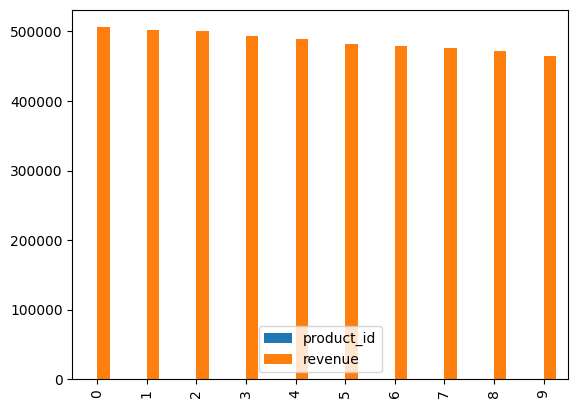

In [48]:
revenue_x_product.head(10).plot(kind="bar")

In [52]:
top_10_products = revenue_x_product.head(10)["product_id"]

df_top10 = df_merged[
    df_merged["product_id"].isin(top_10_products)
]
df_top10.columns

Index(['id_x', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'year', 'hour', 'day', 'month', 'transaction_id', 'product_id', 'id_y',
       'product_name', 'priceDollars', 'colour', 'weight', 'warehouse_id',
       'category', 'brand', 'costDollars', 'launch_date'],
      dtype='object')

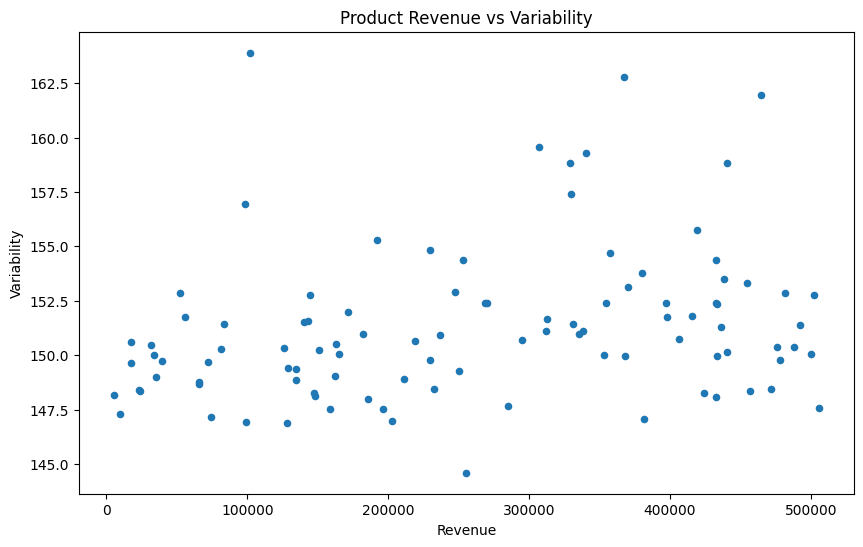

In [56]:
product_stats = (
    df_merged.groupby("product_id")
    .agg(
        revenue=("priceDollars", "sum"),
        variability=("amount", "std")
    )
    .reset_index()
)

ax = product_stats.plot(
    kind="scatter",
    x="revenue",
    y="variability",
    figsize=(10, 6)
)

ax.set_title("Product Revenue vs Variability")
ax.set_xlabel("Revenue")
ax.set_ylabel("Variability")

plt.show()

> Data shows little relationship between a product's total revenue and its transaction variability. Maybe a slight upward trend in total spread.

---


### How Does Sales Activity Vary Across Time Slots Over the Years? (Hourly Patterns)

Guiding Steps


1. Create time slots based on the transaction hour. Use apply.


---


In [57]:
def get_time_slot (hour):
    if 0 <= hour <= 5:
        return "Night"
    elif 6 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 17:
        return "Afternoon"
    else:
        return "Evening"

df_merged["time_slot"] = df_merged["hour"].apply(get_time_slot)


2. Build an aggregated table using `pd.crosstab()`.


In [58]:
time_slot_crosstab = pd.crosstab(
    df_merged["time_slot"], #rows
    df_merged["year"]      #cols
)

time_slot_crosstab

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
time_slot,,,,,,,,,,
Afternoon,6259,6402,6490,6311,6451,6248,6550,6448,6326,6445
Evening,6298,6018,6197,6187,6290,6476,6368,6546,6150,6296
Morning,6201,6257,6239,6093,6441,6312,6578,6254,6329,6332
Night,6232,6227,6071,6359,6251,6611,6512,6529,6513,6291


3. Visualize the results with a heatmap.

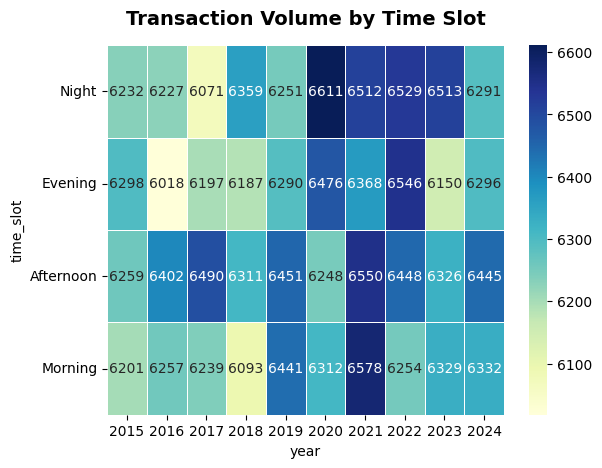

In [59]:
# 1. Define the correct chronological order
time_order = ['Morning', 'Afternoon', 'Evening', 'Night']

# 2. Reindex the DataFrame (change 'index' to 'columns' if the time slots are columns)
ordered_crosstab = time_slot_crosstab.reindex(time_order)

# 3. Plot the ordered heatmap
# ax = sns.heatmap(ordered_crosstab)
ax = sns.heatmap(
    ordered_crosstab,
    cmap='YlGnBu',      # High-contrast palette (alternatives: 'YlGnBu', 'coolwarm')
    annot=True,          # Prints the numbers directly inside the cells
    fmt='d',             # Formats numbers as integers (use '.1f' for floats)
    linewidths=0.5,      # Adds subtle grids between cells to separate colors
)
ax.set_title('Transaction Volume by Time Slot', fontsize=14, pad=15, fontweight='bold')
ax.invert_yaxis()
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.show()

# Level 2 - Relational Analysis and Advanced Patterns



Exercise 1: Product Performance and User Acquisition Analysis

Objective

Analyze product performance by combining revenue, stability, and user acquisition metrics. The goal is to identify business risks related to:

- Excessive revenue concentration
- Dependence on recurring users
- Lack of user base growth

Business Question

Do the products generating the most revenue also drive business growth through new-user acquisition, or does the company mainly depend on recurring users repeatedly buying the same products?

Guiding Steps

1. Combine the necessary tables.
2. Define a **new user** criterion. A transaction is considered a user's first transaction in the system.

```python
is_new_user = True / False
```

3. Aggregate information by product and calculate:

   - Total revenue
   - Number of new users
   - Percentage of new users out of total buyers for the product

4. Create an analytical product classification, for example:

   - **Acquisition Driver**: high new-user acquisition
   - **Recurring Product**: high revenue but low acquisition
   - **Emerging Product**: low revenue but good acquisition
   - **Stagnant Product**: low revenue and low acquisition

5. Build a visualization to analyze the relationship between dimensions.

Example: Scatter Plot

- X-axis → Total revenue per product
- Y-axis → Number of new users
- Point color → Product category

Important Note

The goal is not only to show charts, but to interpret the business implications of failing to attract new users.

---

Exercise 2: Company–User Geographic Analysis and Expansion Opportunities

Objective

Analyze the relationship between:

- Seller company country
- User residence country
- Purchasing flows between countries

Business Question

Is the business mainly driven by local markets (same user-country and company-country), or is there a genuine international expansion opportunity by opening more companies in specific countries?

Guiding Steps

1. Combine the necessary tables.
2. Create a key analysis variable:

```python
local_purchase = True / False
```

3. Analyze overall behavior:

   - Percentage of local vs international transactions
   - Percentage of local vs international revenue

4. User-country analysis:

For each user country calculate:

- Percentage of purchases from companies in the same country
- Percentage of purchases from foreign companies
- Total purchase amount

5. Company-country analysis:

For each company country calculate what percentage of revenue comes from:

- Local users
- Foreign users

6. Choose a visualization that clearly explains the phenomenon.

7. Strategic interpretation:

- In which countries would it make sense to open more local companies?
- Are there countries with demand but limited local supply?
- Is the business overly dependent on companies from a single country?
- Would opening local companies reduce friction or improve conversion?

---

Level 3 - Executive Visualization and Storytelling

Exercise 1: Department Mini Dashboard

Objective

Build a mini dashboard in Python using Google Colab.

The recommended option is:

Option 1 - Single Figure with Subplots (Recommended)

Build one figure containing 4 subplots 